# Standard ConvNeXt fine-tuning

The head-only run gave us a useful fold-0 reference. Here we load that trained five-label head, unfreeze the original ConvNeXt backbone, and fine-tune the complete model without adding a custom block. This is the control for the later architectural comparison.

We first run a few real batches to check the setup. A full run measures its first complete epoch and stops if the projected ten-epoch time exceeds five hours. A fold-0 result is screening evidence, not five-fold cross-validation or a leaderboard score. Training, weight downloads, result writing, and submission-file creation are disabled by default; there is no Kaggle upload step.


In [ ]:
from __future__ import annotations

import hashlib
import os
import platform
import random
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import torch

RUN_TRAINING = os.environ.get('STAGE2_RUN_TRAINING', '0') == '1'
EVAL_CHECKPOINT = os.environ.get('STAGE2_EVAL_CHECKPOINT')
SMOKE_TEST = os.environ.get('STAGE2_SMOKE_TEST', '1') == '1'
PROFILE_ONLY = os.environ.get('STAGE2_PROFILE_ONLY', '0') == '1'
ALLOW_WEIGHT_DOWNLOAD = os.environ.get('STAGE2_ALLOW_WEIGHT_DOWNLOAD', '0') == '1'
USE_WANDB = os.environ.get('STAGE2_USE_WANDB', '1') == '1'
REMOVE_RUNTIME_ENV_AFTER_LOAD = os.environ.get('STAGE2_REMOVE_RUNTIME_ENV_AFTER_LOAD', '0') == '1'
WANDB_MODE = 'online'
WANDB_PROJECT = 'ai301-stage2'
BUILD_SUBMISSION = False
SUBMIT_TO_KAGGLE = False  # No submission API call exists in this notebook.

MODEL_NAME = 'hf-hub:timm/convnext_base.fb_in22k_ft_in1k_384@2b2698d86523262ca8065d0957c7f80d963bb43f'
HEAD_RUN_ID = 'convnext_head_fold0_seed42_colab'
RUN_ID = os.environ.get('STAGE2_RUN_ID', 'convnext_standard_fold0_seed42')
SEED = 42
VALIDATION_FOLD = 0
THRESHOLD = 0.25
IMAGE_SIZE = 384
BATCH_SIZE = 2
EFFECTIVE_BATCH_SIZE = 16
MAX_EPOCHS = 10
PATIENCE = 3
MAX_RUN_HOURS = 5.0
BACKBONE_LR = 1e-5
HEAD_LR = 1e-4
WEIGHT_DECAY = 1e-2
NUM_WORKERS = 0
PRECISION = '32-true'

if EFFECTIVE_BATCH_SIZE % BATCH_SIZE:
    raise ValueError('Effective batch size must be divisible by physical batch size.')
if RUN_TRAINING and EVAL_CHECKPOINT:
    raise ValueError('Choose training or an existing checkpoint, not both.')
if PROFILE_ONLY and (not RUN_TRAINING or SMOKE_TEST):
    raise ValueError('Profile-only mode requires training enabled and smoke mode disabled.')
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Device: {DEVICE}; training: {RUN_TRAINING}; saved checkpoint: {bool(EVAL_CHECKPOINT)}; smoke test: {SMOKE_TEST}; profile only: {PROFILE_ONLY}')


Device: cuda; training: True; saved checkpoint: False; smoke test: False; profile only: True


## Use the same split as before

The validation notebook already assigned every image to one of five folds. We check that `folds.csv` still matches the seed-42 stratified split, then join it to the labels by image ID. This keeps our model comparisons on the same held-out images. Stratification uses the five-label combinations; one combination has only four images, so it cannot appear in every fold.

For the CNN, we keep the whole photo, resize it to fit inside a 384-pixel square, and pad the rest with the checkpoint's mean colour. Training images may be flipped horizontally; validation and test images are left alone. The old embedding baseline used different preprocessing, which matters when we compare scores.

In [ ]:
start = Path(os.environ.get('STAGE2_ROOT', Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents) if (path / 'folds.csv').is_file() and (path / 'stage2' / 'experiment.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Launch Jupyter from this repository or a subdirectory.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from stage2.experiment import LABEL_COLUMNS, ImageDataset, form_submission, read_csv, score_probabilities, split_rows, verify_saved_stratification, write_probabilities, write_run_record, write_submission
from stage2.train import predict_probabilities
from stage2.finetune import FineTuneClassifier, TimedBudgetCheckpoint, load_trained_head

DATA_DIR = ROOT / 'data'
combination_counts = verify_saved_stratification(DATA_DIR, ROOT / 'folds.csv', SEED)
train_rows, validation_rows = split_rows(DATA_DIR, ROOT / 'folds.csv', VALIDATION_FOLD)
test_rows = read_csv(DATA_DIR / 'test.csv', ('image_id',))
sample_rows = read_csv(DATA_DIR / 'sample_submission.csv', ('image_id', *LABEL_COLUMNS))
if {row['image_id'] for row in test_rows} != {row['image_id'] for row in sample_rows}:
    raise ValueError('test.csv and sample_submission.csv have different image IDs.')
required_images = ((train_rows[0], DATA_DIR / 'train'), (validation_rows[0], DATA_DIR / 'train'))
if BUILD_SUBMISSION:
    required_images += ((test_rows[0], DATA_DIR / 'test'),)
for row, directory in required_images:
    if not (directory / f"{row['image_id']}.jpg").is_file():
        raise FileNotFoundError(f'Missing image in {directory}.')
print(f'{len(train_rows):,} train, {len(validation_rows):,} validation, {len(test_rows):,} test images')
print('Saved combination-stratified folds verified:', combination_counts)
print('Positive validation labels:', {label: sum(int(row[label]) for row in validation_rows) for label in LABEL_COLUMNS})

9,808 train, 2,452 validation, 18,673 test images
Saved combination-stratified folds verified: {'00000': 2162, '01000': 4984, '01001': 37, '10000': 4989, '10010': 32, '10100': 42, '10110': 10, '11101': 4}
Positive validation labels: {'Cat': 1015, 'Dog': 1004, 'Moris': 10, 'Motya': 9, 'Biatrix': 8}


## Connect W&B when training starts

For a local run, put `WANDB_API_KEY` in the repo's ignored `.env` file or export it before launching Jupyter. The existing `WB_API_KEY` name also works. In Colab, add a `WANDB_API_KEY` secret and grant the notebook access. The key is read only when online training is enabled; it is never printed or saved in the notebook.

In [ ]:
def ensure_wandb_key() -> None:
    key = os.environ.get('WANDB_API_KEY') or os.environ.get('WB_API_KEY')
    env_file = ROOT / '.env'
    if not key and env_file.is_file():
        for line in env_file.read_text().splitlines():
            name, separator, value = line.partition('=')
            if separator and name.strip() in {'WANDB_API_KEY', 'WB_API_KEY'}:
                key = value.strip().strip("\"'")
                if key:
                    break
    if key:
        os.environ['WANDB_API_KEY'] = key
        if REMOVE_RUNTIME_ENV_AFTER_LOAD and env_file.is_file() and ROOT.is_relative_to('/content'):
            env_file.unlink()
            print('Removed the temporary Colab credential file.')
        return
    try:
        from google.colab import userdata
    except ImportError:
        raise RuntimeError('Set WANDB_API_KEY in the repo .env file or environment.') from None
    try:
        secret = userdata.get('WANDB_API_KEY')
    except Exception as error:
        raise RuntimeError('Add WANDB_API_KEY to Colab Secrets and grant this notebook access.') from error
    if not secret:
        raise RuntimeError('The WANDB_API_KEY Colab Secret is empty.')
    os.environ['WANDB_API_KEY'] = secret

if RUN_TRAINING and USE_WANDB and WANDB_MODE == 'online':
    ensure_wandb_key()
    print('W&B online credential is available (value hidden).')
else:
    print('W&B credential check skipped until online training is enabled.')

W&B online credential is available (value hidden).


## Load the same backbone and trained head

The saved file contains only the head's weights and bias. We recreate the exact pretrained backbone, install those parameters with a strict check, and then leave **both** parts trainable. This head was trained on folds 1–4 and selected on fold 0; using it for another held-out fold would contaminate that fold's evaluation.


In [ ]:
if RUN_TRAINING or EVAL_CHECKPOINT:
    if not ALLOW_WEIGHT_DOWNLOAD:
        os.environ['HF_HUB_OFFLINE'] = '1'
    import timm
    import lightning as L
    from lightning.pytorch.callbacks import EarlyStopping, LearningRateMonitor, ModelCheckpoint
    from lightning.pytorch.loggers import CSVLogger
    from torch.utils.data import DataLoader

    L.seed_everything(SEED, workers=True)
    network = timm.create_model(MODEL_NAME, pretrained=True, num_classes=len(LABEL_COLUMNS))
    preprocessing = timm.data.resolve_model_data_config(network)
    if preprocessing['input_size'][-1] != IMAGE_SIZE:
        raise ValueError(f"Checkpoint expects {preprocessing['input_size']}, not {IMAGE_SIZE}px.")
    head_path = ROOT / 'experiments' / '00_shared_head' / 'checkpoints' / f'{HEAD_RUN_ID}_head.pt'
    load_trained_head(network, head_path)
    for parameter in network.parameters():
        parameter.requires_grad_(True)
    train_data = ImageDataset(train_rows, DATA_DIR / 'train', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'], horizontal_flip=True)
    validation_data = ImageDataset(validation_rows, DATA_DIR / 'train', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'])
    loader_options = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda')
    train_loader = DataLoader(train_data, shuffle=True, **loader_options)
    validation_loader = DataLoader(validation_data, shuffle=False, **loader_options)
    _, image, targets = train_data[0]
    assert image.shape == (3, IMAGE_SIZE, IMAGE_SIZE) and targets.shape == (5,)
    print('Normalization:', preprocessing['mean'], preprocessing['std'])
    print('Trainable parameters:', sum(p.numel() for p in network.parameters() if p.requires_grad))
else:
    print('Model loading skipped.')


INFO: Seed set to 42


INFO:lightning.fabric.utilities.seed:Seed set to 42


Normalization: [0.485, 0.456, 0.406] [0.229, 0.224, 0.225]
Trainable parameters: 87571589


## Check the training path, then time the control

Leave `SMOKE_TEST=True` for the first launch. Eight training batches and four validation batches check backward propagation, optimizer groups, logging, and checkpoint writing; their score is **not** a model result. For a one-epoch timing run, set `SMOKE_TEST=False` and `PROFILE_ONLY=True` with a fresh run ID. It keeps the ten-epoch optimizer schedule but stops after the first complete epoch, including validation and checkpoint writing, regardless of the projection. A full run uses both flags set to false; its five-hour timing gate still applies. Do not treat a profiling score as a completed model result.

The unchanged architecture uses AdamW with separate backbone/head rates, weight decay on weights but not biases or normalization parameters, one epoch of warm-up, then cosine decay. Lightning records loss, F1, AP, and gradient norms in local CSV files and W&B. The model file and photos are not sent to W&B.


In [ ]:
if RUN_TRAINING:
    run_name = RUN_ID + ('_smoke' if SMOKE_TEST else '')
    run_dir = ROOT / 'artifacts' / run_name
    run_dir.mkdir(parents=True, exist_ok=False)
    module = FineTuneClassifier(network, BACKBONE_LR, HEAD_LR, WEIGHT_DECAY, THRESHOLD)
    checkpoint_options = dict(dirpath=run_dir / 'checkpoints', filename='best', monitor='val_macro_f1', mode='max', save_top_k=1, save_weights_only=True)
    checkpoint = ModelCheckpoint(**checkpoint_options) if SMOKE_TEST else TimedBudgetCheckpoint(**checkpoint_options, maximum_hours=MAX_RUN_HOURS, profile_only=PROFILE_ONLY)
    callbacks = [checkpoint, LearningRateMonitor(logging_interval='epoch')]
    if not SMOKE_TEST:
        callbacks.append(EarlyStopping(monitor='val_macro_f1', mode='max', patience=PATIENCE))
    logger = CSVLogger(save_dir=run_dir, name='curves')
    loggers = [logger]
    wandb_logger = None
    if USE_WANDB:
        from lightning.pytorch.loggers import WandbLogger
        wandb_logger = WandbLogger(project=WANDB_PROJECT, name=run_name, save_dir=str(run_dir), offline=False, log_model=False)
        wandb_logger.log_hyperparams({
            'model': MODEL_NAME, 'head_run': HEAD_RUN_ID, 'fold': VALIDATION_FOLD, 'seed': SEED,
            'image_size': IMAGE_SIZE, 'batch_size': BATCH_SIZE, 'effective_batch_size': EFFECTIVE_BATCH_SIZE,
            'backbone_lr': BACKBONE_LR, 'head_lr': HEAD_LR, 'weight_decay': WEIGHT_DECAY,
            'scheduler': 'one-epoch warmup then cosine to 0.1 peak', 'threshold': THRESHOLD,
            'smoke_test': SMOKE_TEST, 'profile_only': PROFILE_ONLY, 'precision': PRECISION, 'runtime_gate_hours': MAX_RUN_HOURS,
        })
        wandb_logger.watch(module.network.get_classifier(), log='gradients', log_freq=50, log_graph=False)
        print('W&B run:', wandb_logger.experiment.url)
        loggers.append(wandb_logger)
    trainer = L.Trainer(
        accelerator=DEVICE.type, devices=1, precision=PRECISION, max_epochs=1 if SMOKE_TEST else MAX_EPOCHS,
        accumulate_grad_batches=EFFECTIVE_BATCH_SIZE // BATCH_SIZE, callbacks=callbacks, logger=loggers,
        limit_train_batches=8 if SMOKE_TEST else 1.0, limit_val_batches=4 if SMOKE_TEST else 1.0,
        num_sanity_val_steps=0, gradient_clip_val=1.0, log_every_n_steps=10,
    )
    if DEVICE.type == 'cuda':
        torch.cuda.reset_peak_memory_stats()
    started = time.perf_counter()
    try:
        trainer.fit(module, train_loader, validation_loader)
    finally:
        if wandb_logger is not None:
            wandb_logger.experiment.finish()
    training_seconds = time.perf_counter() - started
    if SMOKE_TEST:
        if not checkpoint.best_model_path:
            raise RuntimeError('Smoke run produced no checkpoint.')
        restored = FineTuneClassifier.load_from_checkpoint(
            checkpoint.best_model_path, network=network, backbone_lr=BACKBONE_LR,
            head_lr=HEAD_LR, weight_decay=WEIGHT_DECAY, threshold=THRESHOLD,
        ).to(DEVICE).eval()
        with torch.inference_mode():
            restored_logits = restored(image.unsqueeze(0).to(DEVICE))
        if restored_logits.shape != (1, len(LABEL_COLUMNS)) or not torch.isfinite(restored_logits).all():
            raise ValueError('Reloaded smoke checkpoint returned invalid logits.')
        print('Smoke checkpoint reload and forward pass passed.')
    budget_exceeded = not SMOKE_TEST and checkpoint.exceeded_budget
    print(f'Training and validation: {training_seconds / 60:.1f} min; best: {checkpoint.best_model_path}')
    if PROFILE_ONLY or budget_exceeded:
        write_run_record(run_dir / 'timing_gate.json', {
            'run_id': RUN_ID, 'status': 'timing_gate_exceeded' if budget_exceeded else 'profile_only', 'fold': VALIDATION_FOLD,
            'first_epoch_seconds': checkpoint.epoch_seconds[0],
            'projection_margin': checkpoint.projection_margin,
            'projected_seconds': checkpoint.projected_seconds,
            'training_and_validation_seconds': training_seconds,
            'maximum_hours': MAX_RUN_HOURS, 'planned_epochs': MAX_EPOCHS,
            'device': str(DEVICE), 'physical_batch_size': BATCH_SIZE,
            'effective_batch_size': EFFECTIVE_BATCH_SIZE,
            'peak_cuda_allocated_bytes': torch.cuda.max_memory_allocated() if DEVICE.type == 'cuda' else None,
        })
        print('Timing probe complete. This is not a completed experiment.')
else:
    print('No training or checkpoint write.')


TypeError: ModelCheckpoint.__init__() got an unexpected keyword argument 'profile_only'

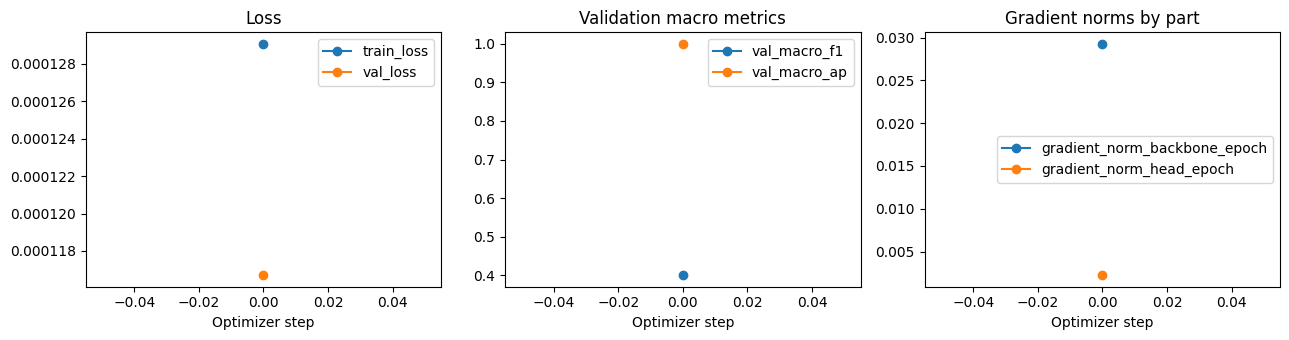

Saved curves: /content/ai301/artifacts/convnext_standard_fold0_seed42_profile1/curves.png


In [ ]:
if RUN_TRAINING:
    import csv
    import matplotlib.pyplot as plt

    with (Path(logger.log_dir) / 'metrics.csv').open(newline='') as file:
        history = list(csv.DictReader(file))
    figure, axes = plt.subplots(1, 3, figsize=(13, 3.5))
    for axis, names, title in zip(
        axes,
        (('train_loss', 'val_loss'), ('val_macro_f1', 'val_macro_ap'), ('gradient_norm_backbone_epoch', 'gradient_norm_head_epoch')),
        ('Loss', 'Validation macro metrics', 'Gradient norms by part'),
    ):
        for name in names:
            points = [(int(row['step']), float(row[name])) for row in history if row.get(name) not in (None, '')]
            if points:
                axis.plot(*zip(*points), marker='o', label=name)
        axis.set(title=title, xlabel='Optimizer step')
        if axis.lines:
            axis.legend()
    figure.tight_layout()
    curves_path = run_dir / 'curves.png'
    figure.savefig(curves_path, dpi=140)
    plt.show()
    print('Saved curves:', curves_path)
else:
    print('No training curves to plot.')

## Evaluate a completed fold, not the smoke test

When the runtime gate permits the full run, reload the best checkpoint and predict all fold-0 images in their saved order. You can also set `STAGE2_EVAL_CHECKPOINT` to a saved full checkpoint and run these cells without training. Report the fixed-threshold macro and per-label F1, average precision, and F1 at 0.5 for context. A stopped timing probe has no reportable quality score.


In [ ]:
if EVAL_CHECKPOINT or (RUN_TRAINING and not SMOKE_TEST and not PROFILE_ONLY and not budget_exceeded):
    checkpoint_path = Path(EVAL_CHECKPOINT).resolve() if EVAL_CHECKPOINT else Path(checkpoint.best_model_path)
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f'Missing full checkpoint: {checkpoint_path}')
    best_module = FineTuneClassifier.load_from_checkpoint(
        checkpoint_path, network=network, backbone_lr=BACKBONE_LR,
        head_lr=HEAD_LR, weight_decay=WEIGHT_DECAY, threshold=THRESHOLD,
    )
    prediction_started = time.perf_counter()
    predicted_ids, validation_probabilities = predict_probabilities(best_module, validation_loader, DEVICE)
    prediction_seconds = time.perf_counter() - prediction_started
    if predicted_ids != [row['image_id'] for row in validation_rows]:
        raise ValueError('Validation loader changed image order.')
    validation_targets = np.asarray([[int(row[label]) for label in LABEL_COLUMNS] for row in validation_rows])
    metrics = score_probabilities(validation_targets, validation_probabilities, THRESHOLD)
    diagnostic_f1 = score_probabilities(validation_targets, validation_probabilities, 0.5)['macro_f1']
    print('Fold-0 metrics:', metrics)
    print('Macro F1 at 0.5:', round(diagnostic_f1, 5))
else:
    print('Full-fold evaluation skipped; smoke and timing-gate scores are not results.')


Full-fold evaluation skipped; smoke and timing-gate scores are not results.


In [ ]:
if RUN_TRAINING and not SMOKE_TEST and not PROFILE_ONLY and not budget_exceeded:
    result_dir = ROOT / 'experiments' / '01_convnext_standard' / 'results'
    probability_path = result_dir / f'{RUN_ID}_val.csv'
    record_path = result_dir / f'{RUN_ID}.json'
    for path in (probability_path, record_path):
        if path.exists():
            raise FileExistsError(f'Refusing to overwrite {path}')
    write_probabilities(probability_path, predicted_ids, validation_probabilities, VALIDATION_FOLD)
    git_commit = subprocess.run(['git', 'rev-parse', 'HEAD'], cwd=ROOT, capture_output=True, text=True, check=True).stdout.strip() if (ROOT / '.git').exists() else None
    source_files = (ROOT / 'notebooks' / '06_convnext_standard.ipynb', ROOT / 'stage2' / 'experiment.py', ROOT / 'stage2' / 'train.py', ROOT / 'stage2' / 'finetune.py')
    source_sha256 = {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest() for path in source_files}
    record = {
        'run_id': RUN_ID, 'experiment': '01_convnext_standard', 'status': 'completed', 'git_commit': git_commit, 'source_sha256': source_sha256,
        'fold': VALIDATION_FOLD, 'seed': SEED,
        'model': {'name': MODEL_NAME, 'variant': 'standard', 'pretrained_checkpoint': MODEL_NAME, 'initial_head_checkpoint': str(head_path.relative_to(ROOT))},
        'data': {'image_size': IMAGE_SIZE, 'transform': 'mean-colour letterbox, bicubic, checkpoint normalization; train horizontal flip p=0.5', 'fold_file': 'folds.csv', 'mean': list(preprocessing['mean']), 'std': list(preprocessing['std'])},
        'training': {'optimizer': f'AdamW(backbone_lr={BACKBONE_LR}, head_lr={HEAD_LR}, weight_decay={WEIGHT_DECAY} except bias/norm, betas=(0.9, 0.999))', 'scheduler': 'one epoch step warmup then cosine to 0.1 peak', 'loss': 'BCEWithLogitsLoss', 'epochs_completed': trainer.fit_loop.epoch_progress.current.completed, 'physical_batch_size': BATCH_SIZE, 'effective_batch_size': EFFECTIVE_BATCH_SIZE, 'precision': PRECISION, 'stage_policy': 'full backbone and classifier trainable', 'checkpoint_selection': 'best validation macro F1 at 0.25', 'gradient_clip_norm': 1.0},
        'hardware': {'device': str(DEVICE), 'system_memory_gb': None, 'cuda_peak_memory_bytes': torch.cuda.max_memory_allocated() if DEVICE.type == 'cuda' else None},
        'metrics': {**metrics, 'macro_f1_at_0_5': diagnostic_f1},
        'timings': {'training_and_validation_seconds': training_seconds, 'epoch_seconds': checkpoint.epoch_seconds, 'first_epoch_projected_seconds': checkpoint.projected_seconds, 'best_checkpoint_prediction_seconds': prediction_seconds},
        'artifacts': {'validation_probabilities_csv': str(probability_path.relative_to(ROOT)), 'full_checkpoint_local': str(Path(checkpoint.best_model_path).relative_to(ROOT)), 'curves_csv': str((Path(logger.log_dir) / 'metrics.csv').relative_to(ROOT))},
        'versions': {'python': platform.python_version(), 'torch': torch.__version__, 'timm': timm.__version__, 'lightning': L.__version__},
        'telemetry': {'wandb_enabled': USE_WANDB, 'wandb_mode': WANDB_MODE if USE_WANDB else None, 'wandb_project': WANDB_PROJECT if USE_WANDB else None, 'wandb_run_id': wandb_logger.version if wandb_logger is not None else None, 'model_upload': False},
        'public_leaderboard_score': None, 'error': None,
    }
    write_run_record(record_path, record)
    print('Saved:', record_path, probability_path, sep='\n')
else:
    print('No full-run artifacts written.')


No full-run artifacts written.


## Make a submission file, if we want one

Only do this after reviewing the validation result. With `BUILD_SUBMISSION=True`, the notebook predicts the test images and writes a CSV in the same order as `sample_submission.csv`. It checks the IDs and column names before writing.

This creates a local file; it does not upload anything. Kaggle submission and recording the public score are separate manual steps. `SUBMIT_TO_KAGGLE` remains false and has no submission code attached to it.

In [ ]:
if BUILD_SUBMISSION:
    if not (EVAL_CHECKPOINT or (RUN_TRAINING and not SMOKE_TEST and not PROFILE_ONLY and not budget_exceeded)):
        raise ValueError('Build a submission only after a complete fold run.')
    test_data = ImageDataset(test_rows, DATA_DIR / 'test', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'])
    test_loader = DataLoader(test_data, shuffle=False, **loader_options)
    test_ids, test_probabilities = predict_probabilities(best_module, test_loader, DEVICE)
    submission_rows = form_submission(DATA_DIR / 'sample_submission.csv', test_ids, test_probabilities, THRESHOLD)
    submission_dir = (ROOT / 'artifacts' / RUN_ID) if RUN_TRAINING else Path(EVAL_CHECKPOINT).resolve().parent.parent
    submission_path = submission_dir / f'{RUN_ID}_submission.csv'
    write_submission(submission_path, submission_rows)
    print('CSV ready for manual review:', submission_path)
else:
    print('No submission CSV built or uploaded.')

No submission CSV built or uploaded.


## Read the comparison carefully

Compare this run only with the head-only fold-0 result on the same images and threshold (macro F1 0.93577). Look at named-pet scores, loss curves, gradient flow, and elapsed time as well as the aggregate score. The old five-fold 0.957 and public 0.92922 numbers answer different questions. A final claim needs a broader evaluation; GradCAM and the matched custom-block run follow this control.
